# Preliminary data analysis: is the recorded data usable?

**Questions**

1. Is the recording technically sound (probe captured, no clipping, correct timing)?
2. After filtering, does silent mouthing produce a visible echo change?
3. Can the classes be told apart, and how well, with this amount of data?

Set `PARTICIPANT` / `SESSION` in the first cell to analyse another recording. Figures are
saved to `analysis/figures/`. Run from the repository root or from `analysis/`.

**How to read the evaluation numbers.** Each class was recorded as 2 *takes* of 5
back-to-back repetitions. Repetitions within a take are near-duplicates, so every
classifier below is evaluated **across takes**: train on one take of each class, test
on the other, then swap. A random clip split would leak and look much better than it
really is; that comparison is shown once in §7.

In [1]:
import sys, csv, json, warnings
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal, stats
warnings.filterwarnings("ignore")

REPO = Path.cwd().parent if Path.cwd().name == "analysis" else Path.cwd()
sys.path.insert(0, str(REPO / "src"))
from echospeak.config import load_config
from echospeak.audio import read_wav
from echospeak.probe import demodulate

PARTICIPANT, SESSION = "P02", "S1"
SESSION_DIR = REPO / "data" / "raw" / PARTICIPANT / SESSION
FIG = REPO / "analysis" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

cfg = load_config(REPO / "configs" / "default.yaml")
meta = json.loads((SESSION_DIR / "session.json").read_text())
cues = [c for c in csv.DictReader(open(SESSION_DIR / "cues.csv")) if c["status"] == "ok"]
on = [c for c in cues if c["probe"] == "on"]
off = [c for c in cues if c["probe"] == "off"]
LABELS = list(meta["labels"])
WORDS = [l for l in LABELS if l in cfg.data.commands]
NONCMD = [l for l in LABELS if l not in WORDS]
R = cfg.features.baseband_rate          # 500 Hz complex baseband
TONES = cfg.probe.tones_hz

plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 10, "font.size": 9})
def savefig(name):
    plt.savefig(FIG / f"{PARTICIPANT}_{name}.png", dpi=110, bbox_inches="tight")

print(f"{PARTICIPANT}/{SESSION} on {meta['device']}: {len(on)} probe-on clips, {len(off)} probe-off clips")
print("clips per class:", {l: sum(c['label'] == l for c in on) for l in LABELS})
print("takes per class:", {l: len({c['take'] for c in on if c['label'] == l}) for l in LABELS})

P02/S1 on Mac16,1: 120 probe-on clips, 12 probe-off clips
clips per class: {'BACK': 10, 'MENU': 10, 'BANANA': 10, 'GO': 10, 'OKAY': 10, 'STOP': 10, 'NEXT': 10, 'APPLE': 10, 'REST': 10, 'CHEWING': 10, 'YAWNING': 10, 'TALKING': 10}
takes per class: {'BACK': 2, 'MENU': 2, 'BANANA': 2, 'GO': 2, 'OKAY': 2, 'STOP': 2, 'NEXT': 2, 'APPLE': 2, 'REST': 2, 'CHEWING': 2, 'YAWNING': 2, 'TALKING': 2}


## 1. Recording quality

duration 11.5 min @ 48000 Hz; audio dropouts: 0
sound check: tone SNR [62.6, 66.0, 66.2, 66.1, 65.9, 65.1, 65.3, 66.2] dB (need >= 20), peak 0.797, beep heard: True
clipped samples: 82 (all before 10.0 s) | first recorded take starts at 104 s


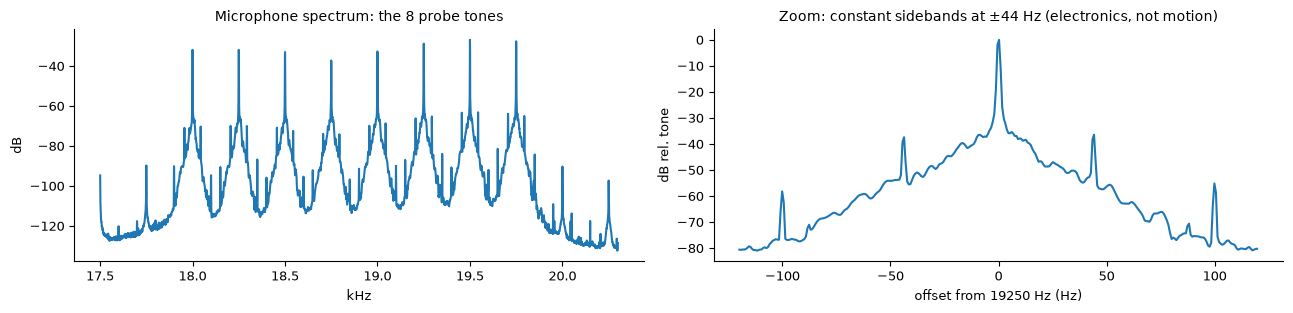

In [2]:
audio, sr = read_wav(SESSION_DIR / "session.wav")
sc = meta["sound_check"]
clipped = np.where(np.abs(audio) > 0.98)[0] / sr
first_take = min(int(c["go_sample"]) for c in on) / sr
print(f"duration {len(audio)/sr/60:.1f} min @ {sr} Hz; audio dropouts: {meta['xruns']}")
print(f"sound check: tone SNR {sc['tone_snr_db']} dB (need >= 20), peak {sc['peak_level']}, beep heard: {sc['beep_heard']}")
print(f"clipped samples: {len(clipped)} (all before {clipped.max():.1f} s)" if len(clipped) else "no clipping",
      f"| first recorded take starts at {first_take:.0f} s")

seg = audio[int(first_take*sr): int((first_take+240)*sr)]
f, p = signal.welch(seg, fs=sr, nperseg=2**16)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.2))
m = (f > 17500) & (f < 20300)
ax[0].plot(f[m]/1000, 10*np.log10(p[m])); ax[0].set_xlabel("kHz"); ax[0].set_ylabel("dB")
ax[0].set_title("Microphone spectrum: the 8 probe tones")
tone = TONES[5]; m = np.abs(f - tone) < 120
ax[1].plot(f[m] - tone, 10*np.log10(p[m] / p[np.argmin(np.abs(f - tone))]))
ax[1].set_xlabel(f"offset from {tone:.0f} Hz (Hz)"); ax[1].set_ylabel("dB rel. tone")
ax[1].set_title("Zoom: constant sidebands at ±44 Hz (electronics, not motion)")
plt.tight_layout(); savefig("1_spectrum"); plt.show()

## 2. Filtering: from raw audio to an echo-motion signal

The motion is invisible in the raw audio. The pipeline (same as `src/echospeak/probe.py`)
does three things:

1. **Coherent demodulation:** each tone is mixed down to complex baseband and
   low-pass filtered at 110 Hz, giving `h_k(t)` at 500 Hz.
2. **Static removal:** `rel_k = h_k / (2 s moving average of h_k) − 1`. This is the echo
   change relative to the slowly varying direct path. It removes volume and posture drift.
3. **Low-pass at 15 Hz:** lip and jaw motion is slow; this removes broadband noise.

In [3]:
def demod_session(x, sr, chunk_s=60, overlap_s=2):
    step, ov, dec = int(chunk_s*sr), int(overlap_s*sr), sr // R
    parts = []
    for a in range(0, len(x), step):
        lo = max(0, a - ov)
        b = demodulate(x[lo: a + step + ov], sr, cfg.probe, cfg.features)
        parts.append(b[:, (a - lo)//dec: (a - lo)//dec + min(step, len(x) - a)//dec])
    return np.concatenate(parts, axis=1)

bb = demod_session(audio, sr)                      # [8 tones, N] complex
k = np.ones(int(2.0*R)) / int(2.0*R)
static = np.stack([np.convolve(b, k, mode="same") for b in bb])
rel = bb / static - 1
relL = signal.sosfiltfilt(signal.butter(4, 15, fs=R, output="sos"), rel, axis=1)
speed = np.abs(np.diff(relL, axis=1)) * R          # per-tone echo-change speed
speed_s = np.stack([np.convolve(v, np.ones(25)/25, mode="same") for v in speed])
go = lambda c: int(c["go_sample"]) * R // sr      # cue -> baseband index
print("baseband:", bb.shape, "| median tone amplitude:", np.round(np.median(np.abs(bb), 1), 3))

baseband: (8, 345418) | median tone amplitude: [0.035 0.038 0.032 0.019 0.034 0.055 0.065 0.065]


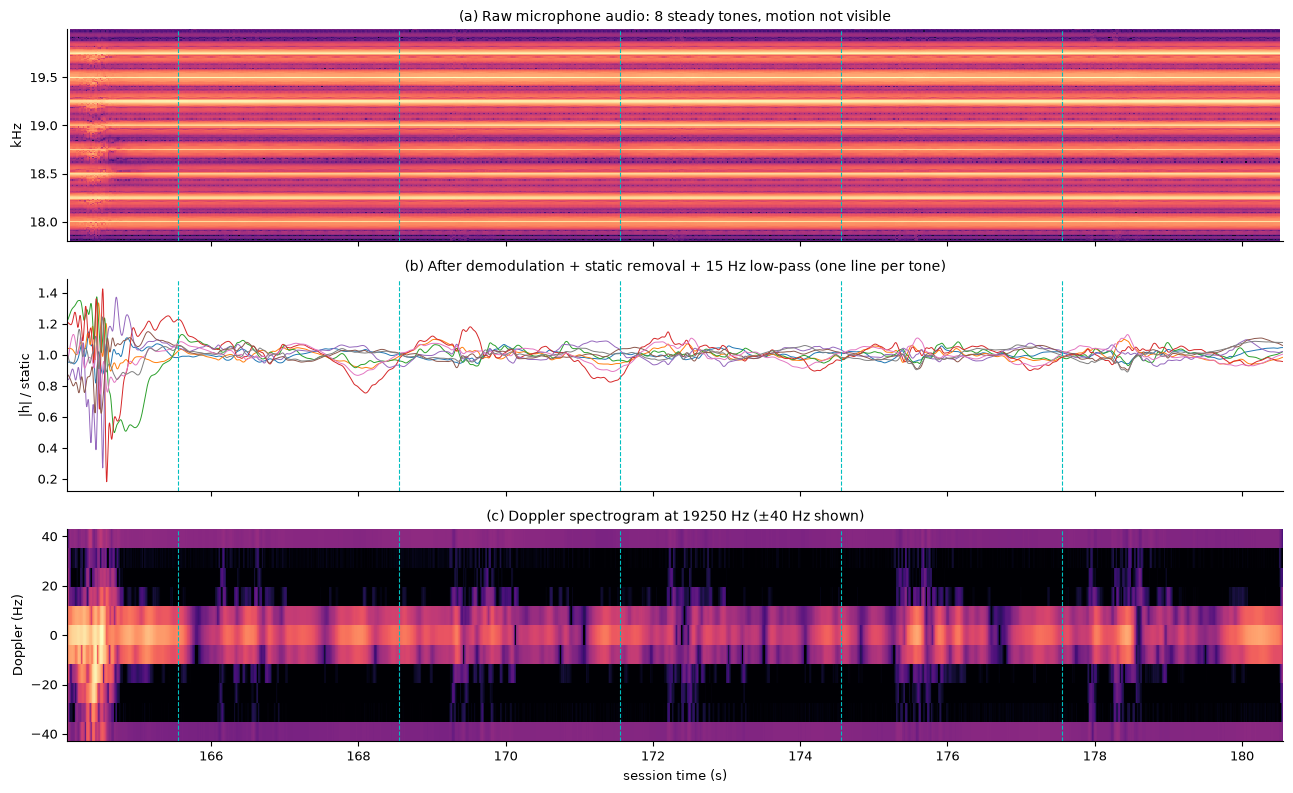

In [4]:
take = next(c["take"] for c in on if c["label"] == "NEXT")
reps = [c for c in on if c["take"] == take]
t0, t1 = go(reps[0]) / R - 1.5, go(reps[-1]) / R + 3
a, b = int(t0*sr), int(t1*sr)
fig, ax = plt.subplots(3, 1, figsize=(13, 8), sharex=True)
f_, t_, S = signal.spectrogram(audio[a:b], fs=sr, nperseg=4096, noverlap=3072)
m = (f_ > 17800) & (f_ < 20000)
ax[0].pcolormesh(t_ + t0, f_[m]/1000, 10*np.log10(S[m] + 1e-14), shading="auto", cmap="magma")
ax[0].set_ylabel("kHz"); ax[0].set_title("(a) Raw microphone audio: 8 steady tones, motion not visible")
ia, ib = int(t0*R), int(t1*R); tt = np.arange(ia, ib) / R
ax[1].plot(tt, np.abs(1 + relL[:, ia:ib]).T, lw=0.7)
ax[1].set_ylabel("|h| / static"); ax[1].set_title("(b) After demodulation + static removal + 15 Hz low-pass (one line per tone)")
f2, t2, S2 = signal.stft(rel[5, ia:ib], fs=R, nperseg=64, noverlap=59, return_onesided=False)
S2 = np.fft.fftshift(np.abs(S2)**2, 0); f2 = np.fft.fftshift(f2); m2 = np.abs(f2) <= 40
ax[2].pcolormesh(t2 + t0, f2[m2], 10*np.log10(S2[m2] + 1e-12), shading="auto", cmap="magma",
                 vmin=np.percentile(10*np.log10(S2[m2] + 1e-12), 30))
ax[2].set_ylabel("Doppler (Hz)"); ax[2].set_xlabel("session time (s)")
ax[2].set_title(f"(c) Doppler spectrogram at {TONES[5]:.0f} Hz (±40 Hz shown)")
for c in reps:
    for x_ in ax: x_.axvline(go(c)/R, color="c", ls="--", lw=0.8)
plt.tight_layout(); savefig("2_filtering_NEXT_take"); plt.show()

## 3. Session overview

Tone amplitude over the whole session, with the takes marked. The probe-off round at the
end shows the tones vanishing during each take.

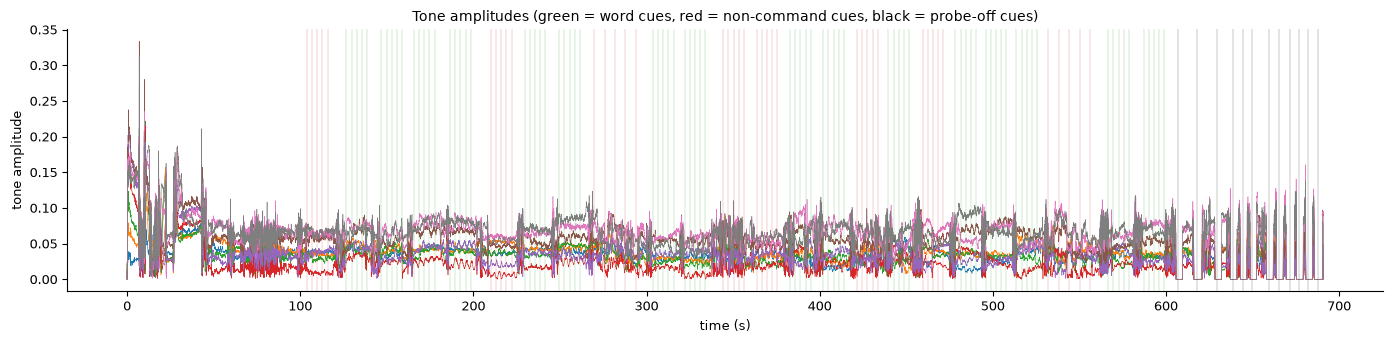

In [5]:
fig, ax = plt.subplots(figsize=(14, 3.5))
tt = np.arange(bb.shape[1]) / R
ax.plot(tt[::10], np.abs(bb[:, ::10]).T, lw=0.4)
colors = {True: "tab:green", False: "tab:red"}
for c in cues:
    ax.axvline(go(c)/R, color="k" if c["probe"] == "off" else colors[c["label"] in WORDS], lw=0.3, alpha=0.5)
ax.set_xlabel("time (s)"); ax.set_ylabel("tone amplitude")
ax.set_title("Tone amplitudes (green = word cues, red = non-command cues, black = probe-off cues)")
plt.tight_layout(); savefig("3_session_overview"); plt.show()

## 4. Average echo response per class

Echo-change speed, summed over tones and aligned to the beep (t = 0). It is normalised
by each repetition's own pre-beep level. Grey lines are single repetitions; black is the
median of the 10.

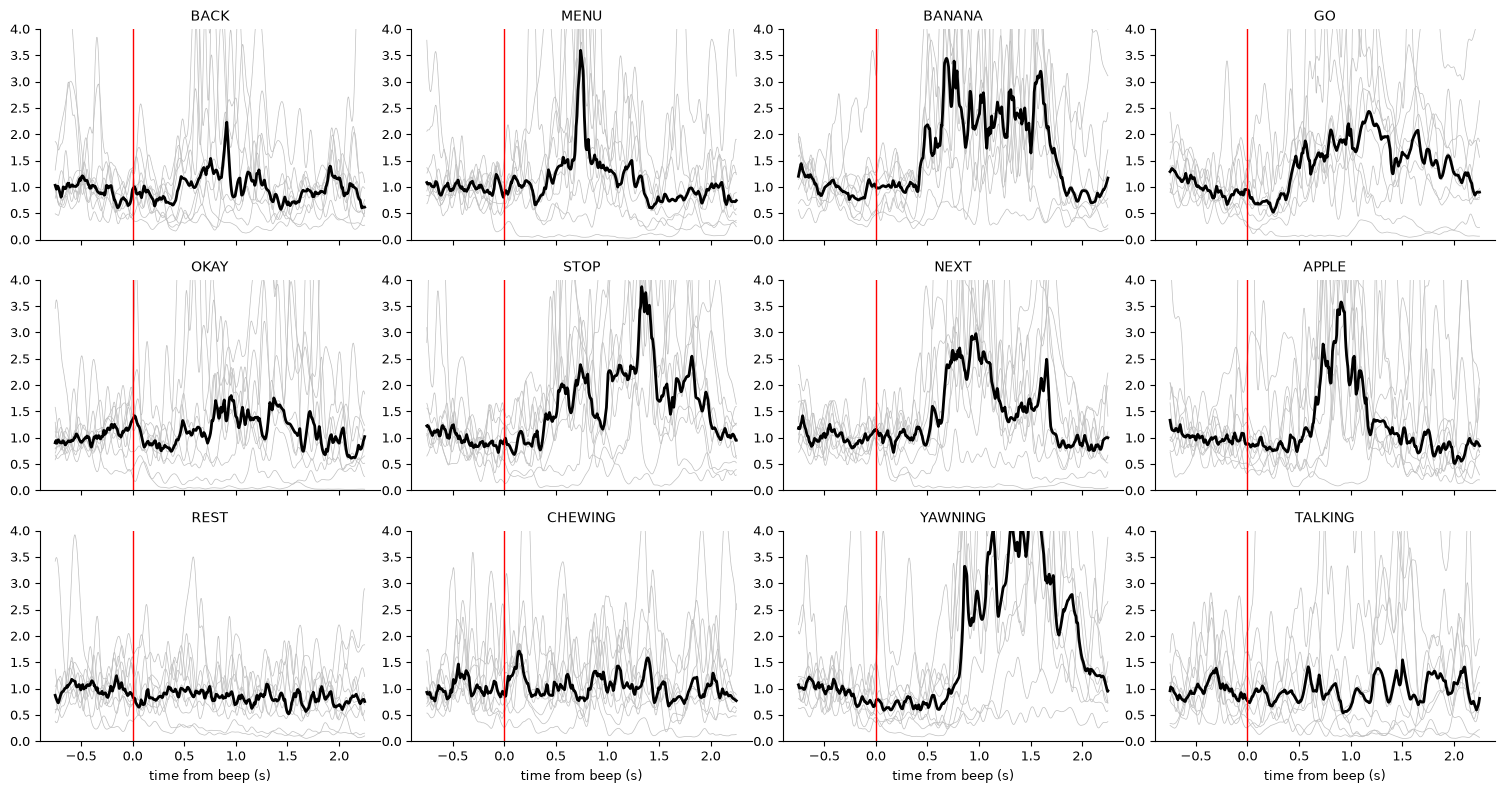

class    median post/pre   share of reps > 1.5x
BACK           1.38            50%
MENU           1.61            60%
BANANA         2.38            90%
GO             1.76            80%
OKAY           1.46            40%
STOP           2.48            70%
NEXT           2.08            80%
APPLE          1.68            60%
REST           0.91             0%
CHEWING        1.02            10%
YAWNING        2.93            60%
TALKING        1.07            30%


In [6]:
total = speed_s.sum(0)
tw = np.arange(-0.75, 2.25, 1/R)
fig, axes = plt.subplots(3, 4, figsize=(15, 8), sharex=True)
rows = []
for ax, lab in zip(axes.flat, LABELS):
    tr = np.array([total[go(c) - int(.75*R): go(c) + int(2.25*R)] for c in on if c["label"] == lab])
    base = np.median(tr[:, :int(.6*R)], 1, keepdims=True)
    trn = tr / base
    ax.plot(tw, trn.T, color="0.75", lw=0.5); ax.plot(tw, np.median(trn, 0), "k", lw=2)
    ax.axvline(0, color="r", lw=1); ax.set_ylim(0, 4); ax.set_title(lab)
    pre = tr[:, int(.1*R): int(.65*R)].mean(1); post = tr[:, int(1.15*R): int(2.35*R)].mean(1)
    rows.append((lab, np.median(post/pre), (post/pre > 1.5).mean()))
for ax in axes[-1]: ax.set_xlabel("time from beep (s)")
plt.tight_layout(); savefig("4_class_responses"); plt.show()
print(f"{'class':8s} median post/pre   share of reps > 1.5x")
for lab, r, frac in rows:
    print(f"{lab:8s} {r:10.2f}   {frac:12.0%}")

## 5. Single-repetition detectability

Can one repetition of a word be told apart from REST, using only the motion increase
after the beep (0.4–1.6 s) relative to before it?

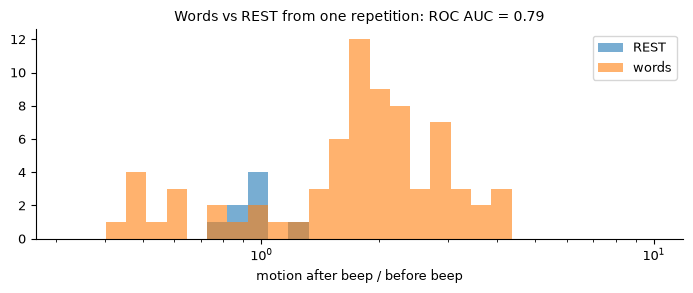

word repetitions with >1.5x motion increase: 66%; REST: 0%


In [7]:
from sklearn.metrics import roc_auc_score
def ratio(c):
    v = speed_s.sum(0); g = go(c)
    return v[g + int(.4*R): g + int(1.6*R)].mean() / v[g - int(.65*R): g - int(.1*R)].mean()
lab = np.array([c["label"] for c in on]); r = np.array([ratio(c) for c in on])
isw = np.isin(lab, WORDS); m = isw | (lab == "REST")
auc = roc_auc_score(isw[m], r[m])
fig, ax = plt.subplots(figsize=(7, 3))
bins = np.logspace(-0.5, 1, 30)
ax.hist(r[lab == "REST"], bins, alpha=.6, label="REST"); ax.hist(r[isw], bins, alpha=.6, label="words")
ax.set_xscale("log"); ax.set_xlabel("motion after beep / before beep"); ax.legend()
ax.set_title(f"Words vs REST from one repetition: ROC AUC = {auc:.2f}")
plt.tight_layout(); savefig("5_detectability"); plt.show()
print(f"word repetitions with >1.5x motion increase: {(r[isw] > 1.5).mean():.0%}; REST: {(r[lab=='REST'] > 1.5).mean():.0%}")

## 6. Class signatures

The mean echo-motion envelope per class (10 Hz bins, log relative to the pre-beep
baseline). Distinct rows mean distinct temporal patterns.

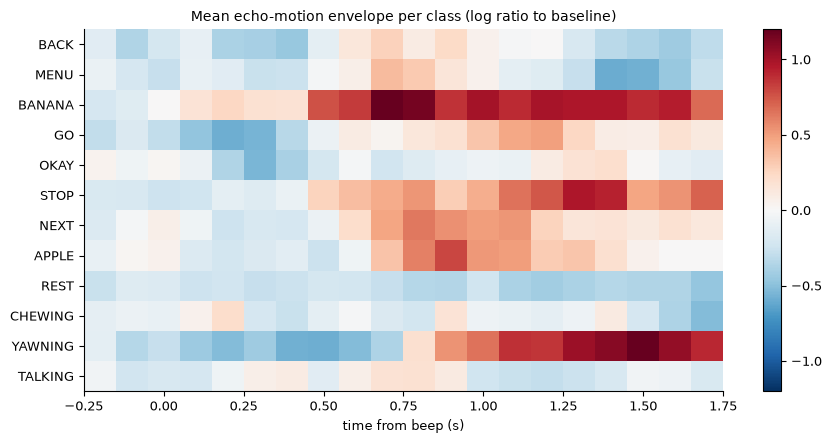

In [8]:
def envelope(c, per_tone=False):
    g = go(c)
    w = speed_s[:, g - int(.25*R): g + int(1.75*R)]
    base = np.median(speed_s[:, g - int(.7*R): g - int(.1*R)], 1, keepdims=True)
    w = np.log(w / base + 1e-3).reshape(8, 20, -1).mean(2)
    return w.ravel() if per_tone else w.mean(0)
E = np.array([envelope(c) for c in on])
M = np.array([E[lab == l].mean(0) for l in LABELS])
fig, ax = plt.subplots(figsize=(9, 4.5))
im = ax.imshow(M, aspect="auto", cmap="RdBu_r", vmin=-1.2, vmax=1.2, extent=[-0.25, 1.75, len(LABELS) - .5, -.5])
ax.set_yticks(range(len(LABELS)), LABELS); ax.set_xlabel("time from beep (s)")
ax.set_title("Mean echo-motion envelope per class (log ratio to baseline)")
plt.colorbar(im); plt.tight_layout(); savefig("6_class_templates"); plt.show()

## 7. How separable are the classes right now? (cross-take evaluation)

Four hand-made feature sets, each with three simple classifiers:

| Feature set | What it contains |
|---|---|
| `static` | mean echo level per tone; a control for posture confounds, which should be at chance |
| `energy` | per-tone motion statistics |
| `trajectory` | the low-passed relative echo, at 20 Hz |
| `envelope` | the motion envelope from §6 |

Training uses 5 repetitions per class; testing uses the other take.

In [9]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import confusion_matrix

def window(c):
    g = go(c); return relL[:, g - int(.25*R): g + int(1.75*R)][:, ::25]
FEATURES = {
    "static": lambda c: np.log(np.abs(bb[:, go(c) - int(.25*R): go(c) + int(1.75*R)]).mean(1)),
    "energy": lambda c: np.concatenate([np.abs(window(c)).mean(1), np.abs(window(c)).std(1),
                                        np.abs(np.diff(window(c), axis=1)).mean(1)]),
    "trajectory": lambda c: np.concatenate([np.abs(1 + window(c)).ravel() - 1, np.angle(1 + window(c)).ravel()]),
    "envelope": lambda c: envelope(c, per_tone=False),
}
def model(name, d):
    return {"logreg": make_pipeline(StandardScaler(), PCA(min(30, d)), LogisticRegression(C=0.1, max_iter=3000)),
            "svm": make_pipeline(StandardScaler(), SVC(C=1)),
            "forest": RandomForestClassifier(500, random_state=0)}[name]

y = np.array([LABELS.index(c["label"]) for c in on])
first = {}
for c in on: first.setdefault(c["label"], c["take"])
fold = np.array([0 if c["take"] == first[c["label"]] else 1 for c in on])

def cross_take(X, mask, name, return_pred=False):
    pred = np.full(len(y), -1); accs = []
    for f in (0, 1):
        tr, te = mask & (fold != f), mask & (fold == f)
        m = model(name, X.shape[1]).fit(X[tr], y[tr]); pred[te] = m.predict(X[te])
        accs.append((pred[te] == y[te]).mean())
    return (np.mean(accs), pred) if return_pred else np.mean(accs)

isword = np.isin(lab, WORDS); allm = np.ones(len(y), bool)
results = {}
print(f"{'features':11s} {'model':7s}  all 12 classes (chance {1/len(LABELS):.2f})   8 words (chance {1/len(WORDS):.2f})")
for fname, fn in FEATURES.items():
    X = np.array([fn(c) for c in on])
    for mname in ("logreg", "svm", "forest"):
        a12, a8 = cross_take(X, allm, mname), cross_take(X, isword, mname)
        results[(fname, mname)] = (a12, a8)
        print(f"{fname:11s} {mname:7s}  {a12:24.2f}   {a8:20.2f}")
Xt = np.array([FEATURES["trajectory"](c) for c in on])
leaky = cross_val_score(model("logreg", Xt.shape[1]), Xt, y, cv=StratifiedKFold(5, shuffle=True, random_state=0)).mean()
print(f"\nfor comparison, a leaky random 5-fold split (trajectory + logreg): {leaky:.2f}  <- inflated by near-duplicate repetitions")

features    model    all 12 classes (chance 0.08)   8 words (chance 0.12)
static      logreg                       0.03                   0.06
static      svm                          0.07                   0.11


static      forest                       0.03                   0.06
energy      logreg                       0.12                   0.17
energy      svm                          0.17                   0.17


energy      forest                       0.20                   0.14
trajectory  logreg                       0.12                   0.21
trajectory  svm                          0.18                   0.21


trajectory  forest                       0.12                   0.14
envelope    logreg                       0.14                   0.17
envelope    svm                          0.14                   0.12


envelope    forest                       0.17                   0.24

for comparison, a leaky random 5-fold split (trajectory + logreg): 0.32  <- inflated by near-duplicate repetitions


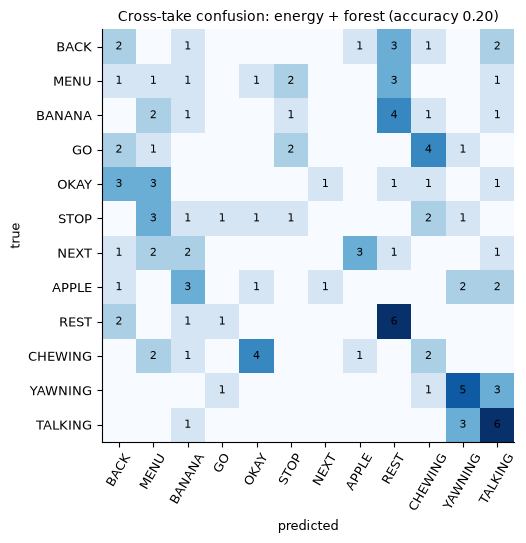

In [10]:
best = max((k for k in results if k[0] != "static"), key=lambda k: results[k][0])
X = np.array([FEATURES[best[0]](c) for c in on])
acc, pred = cross_take(X, allm, best[1], return_pred=True)
cm = confusion_matrix(y, pred, labels=range(len(LABELS)))
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(LABELS)), LABELS, rotation=60); ax.set_yticks(range(len(LABELS)), LABELS)
for i in range(len(LABELS)):
    for j in range(len(LABELS)):
        if cm[i, j]: ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8)
ax.set_xlabel("predicted"); ax.set_ylabel("true")
ax.set_title(f"Cross-take confusion: {best[0]} + {best[1]} (accuracy {acc:.2f})")
plt.tight_layout(); savefig("7_confusion"); plt.show()

## 8. The actual training pipeline (CNN) on this session

`echospeak cv --protocol trial` with take-aware folds: 2 folds, so each fold trains on
one take per class. This is the same model that will be trained on the full dataset,
here with only 60 training clips.

In [11]:
import tempfile
from echospeak.data import read_manifest
from echospeak.evaluate import run_cv
clips = [c for c in read_manifest(REPO / "data" / "manifest.csv")
         if c.participant == PARTICIPANT and c.session == SESSION and c.probe == "on"]
cnn = {}
for temporal in ("none", "transformer"):
    c_ = load_config(REPO / "configs" / "default.yaml", [f"model.temporal={temporal}"])
    with tempfile.TemporaryDirectory() as tmp:
        s = run_cv([c_], clips, "trial", tmp, n_folds=2, cache_dir=str(REPO / "analysis" / ".cache"), log=lambda *a: None)
    cnn[temporal] = s["accuracy_mean"]
    print(f"CNN ({temporal:11s}) cross-take accuracy: {s['accuracy_mean']:.2f}  (chance {1/len(LABELS):.2f})")

CNN (none       ) cross-take accuracy: 0.15  (chance 0.08)


CNN (transformer) cross-take accuracy: 0.15  (chance 0.08)


## 9. Probe-off control

The last round was recorded with the probe silent. Without the probe there is no echo
to measure: the tone amplitude collapses, and a classifier trained on probe-on data
should not do better than chance on these clips.

In [12]:
amp_on = np.array([np.abs(bb[:, go(c): go(c) + R]).mean() for c in on])
amp_off = np.array([np.abs(bb[:, go(c): go(c) + R]).mean() for c in off])
print(f"mean tone amplitude during takes: probe on {amp_on.mean():.4f}, probe off {amp_off.mean():.5f} "
      f"({20*np.log10(amp_off.mean()/amp_on.mean()):.0f} dB)")
Xon = np.array([FEATURES['energy'](c) for c in on]); Xoff = np.array([FEATURES['energy'](c) for c in off])
yoff = np.array([LABELS.index(c["label"]) for c in off])
clf = model("forest", Xon.shape[1]).fit(Xon, y)
print(f"classifier trained on probe-on clips, tested on {len(off)} probe-off clips: "
      f"accuracy {(clf.predict(Xoff) == yoff).mean():.2f} (chance {1/len(LABELS):.2f})")

mean tone amplitude during takes: probe on 0.0433, probe off 0.00000 (-86 dB)


classifier trained on probe-on clips, tested on 12 probe-off clips: accuracy 0.08 (chance 0.08)


## 10. Conclusions

See `analysis/README.md` for the written summary of this run. The short version:

* **The recording is technically sound.**
  * Tone SNR is above 60 dB.
  * There are no dropouts, and the only clipping happens before the first take.
  * The GO beeps align the clips.
  * There is one artefact: constant ±44 Hz sidebands from the electronics, which do not
    move with motion.
* **Mouthing is visible in the filtered echo.**
  * Every word produces a time-locked response 0.4–1.6 s after the beep (§4).
  * Different words have different shapes (§6).
  * Most single repetitions are detectable against REST (§5).
* **12-way classification from one session is near chance plus a little.** Training on
  5 repetitions per class and testing on another take leaves very little data. The
  per-repetition signal is also noisy relative to the between-take variation. This
  mostly measures data quantity. Accuracy has to be re-evaluated once there are more
  takes per class and more sessions.